# Originación: mezcla de cartera, tasas y contracción

## Resumen de la ejecución

Datos sintéticos; resultados de esta ejecución:

- **Grupos simulados:** 80
- **Cambios inyectados:** 4
- **Grupos revisados por criterio:** 8
- **Mayor residuo ajustado:** 9.7

Los supuestos, límites y contraejemplos se explican junto a cada experimento.

## Objetivo y método

¿Un canal tiene más omisiones o simplemente atiende una población distinta? Comparamos tasas brutas, esperadas según mezcla y contracción hacia una referencia conocida.

### Supuestos y población

Eventos de omisión de control simulados en 80 grupos, no etiquetas de fraude. Dos productos con tasas base diferentes. Las probabilidades de referencia son conocidas por el simulador y no se estiman con el mismo resultado a evaluar.

Todos los datos son sintéticos. Las cifras ilustran mecanismos y no constituyen desempeño observado en una entidad. Fecha de desarrollo: 21 de octubre de 2026.

## Entorno reproducible

Ejecutar en orden, desde esta carpeta o una subcarpeta de la línea de fraude. La semilla y los parámetros quedan en las celdas; no se consulta internet ni se leen datos de clientes.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import average_precision_score, brier_score_loss
base = next(p for p in [Path.cwd(), *Path.cwd().parents] if p.name == 'fraud-and-anomaly-research')
sys.path.insert(0, str(base / 'loss-minimization-engine'))
from src.engine import Case, Action, Scenario, optimize, expected_cost, shared_entity_count
rng = np.random.default_rng(20261021)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False, 'grid.alpha': .25})
BLUE, TEAL, GOLD, PURPLE = '#386A96', '#217A72', '#B37D2E', '#73579D'
pd.options.display.float_format = '{:,.4f}'.format

No event loop hook running.


## 1. El denominador y la mezcla cambian la tasa


$$E_g=\sum_i p_{ig}^{ref},\quad O_g=\sum_i y_{ig},\quad z_g=\frac{O_g-E_g}{\sqrt{\sum_i p_{ig}^{ref}(1-p_{ig}^{ref})}}.$$

La varianza supone independencia condicional. En lotes dependientes o sobredispersión puede subestimar incertidumbre; no se usa como prueba universal de fraude.

,grupo,n,mezcla_alta,O,E,tasa_bruta,tasa_esperada,z,anomalia_simulada
28,28,17,0.9412,4,2.4250,0.2353,0.1426,1.0962,False
33,33,263,0.3384,56,17.7000,0.2129,0.0673,9.7005,True
52,52,33,0.4848,7,2.8250,0.2121,0.0856,2.6649,True
10,10,24,0.4583,5,1.9750,0.2083,0.0823,2.3070,False
41,41,10,0.7000,2,1.1250,0.2000,0.1125,0.8904,False
60,60,74,0.8108,14,9.3500,0.1892,0.1264,1.6449,False
40,40,11,0.8182,2,1.4000,0.1818,0.1273,0.5486,False
7,7,45,0.0000,8,1.1250,0.1778,0.0250,6.5644,True


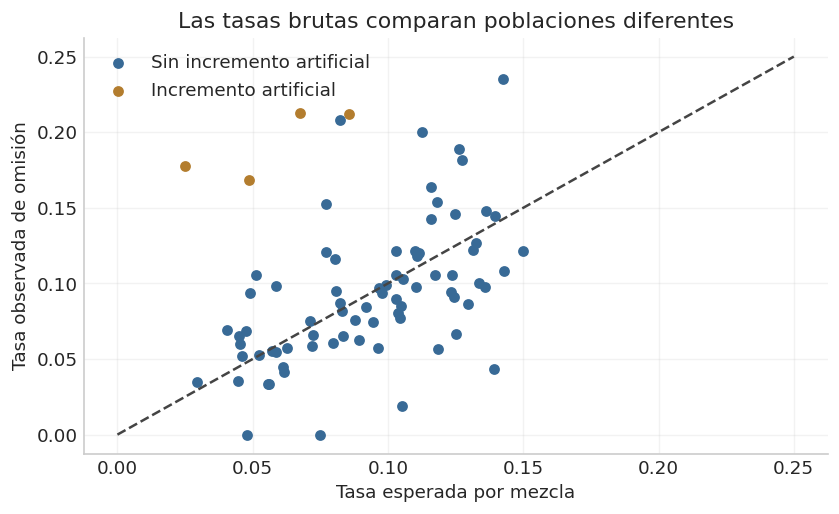

In [2]:
groups=80
volumes=rng.integers(8,300,groups)
mixture=rng.beta(1.5,1.5,groups)
anomalous=np.zeros(groups,dtype=bool);anomalous[[7,18,33,52]]=True
records=[]
for g in range(groups):
    high=rng.binomial(1,mixture[g],volumes[g])
    reference=np.where(high==1,.15,.025)
    actual=np.minimum(1,reference+.13*anomalous[g])
    observed=rng.binomial(1,actual).sum()
    expected=reference.sum();variance=np.sum(reference*(1-reference))
    records.append({'grupo':g,'n':volumes[g],'mezcla_alta':high.mean(),'O':observed,'E':expected,
                    'tasa_bruta':observed/volumes[g],'tasa_esperada':expected/volumes[g],
                    'z':(observed-expected)/np.sqrt(variance),'anomalia_simulada':anomalous[g]})
process=pd.DataFrame(records)
display(process.sort_values('tasa_bruta',ascending=False).head(8))
fig,ax=plt.subplots()
for flag,color,label in [(False,BLUE,'Sin incremento artificial'),(True,GOLD,'Incremento artificial')]:
    subset=process[process['anomalia_simulada']==flag]
    ax.scatter(subset['tasa_esperada'],subset['tasa_bruta'],color=color,label=label,s=30)
ax.plot([0,.25],[0,.25],color='#444444',linestyle='--')
ax.set(xlabel='Tasa esperada por mezcla',ylabel='Tasa observada de omisión',title='Las tasas brutas comparan poblaciones diferentes');ax.legend();plt.show()

Las cuatro anomalías se inyectan por construcción. Un punto sobre la diagonal puede aparecer por azar, una política nueva o un problema de registro. El gráfico compara un evento de control, no prueba intención ni fraude.

## 2. Contracción explícita de grupos pequeños


Con una referencia $p_g^{ref}=E_g/n_g$ y fuerza previa $\tau$, una media regularizada es
$$\tilde p_g=\frac{O_g+\tau p_g^{ref}}{n_g+\tau}.$$

Aquí es una regla de contracción motivada por beta-binomial. No es un modelo jerárquico completo: ni $\tau$ ni la referencia se estiman de forma bayesiana en este notebook.

,grupo,n,tasa_bruta,tasa_esperada,tasa_contraida,z,anomalia_simulada
33,33,263,0.2129,0.0673,0.1937,9.7005,True
18,18,190,0.1684,0.0487,0.1476,7.8759,True
7,7,45,0.1778,0.0250,0.1059,6.5644,True
2,2,235,0.0936,0.0489,0.0871,3.2608,False
52,52,33,0.2121,0.0856,0.1428,2.6649,True
17,17,72,0.1528,0.0771,0.1257,2.4750,False
10,10,24,0.2083,0.0823,0.1296,2.3070,False
63,63,259,0.1158,0.0805,0.1111,2.1464,False
60,60,74,0.1892,0.1264,0.1671,1.6449,False
11,11,91,0.1209,0.0772,0.1075,1.6046,False


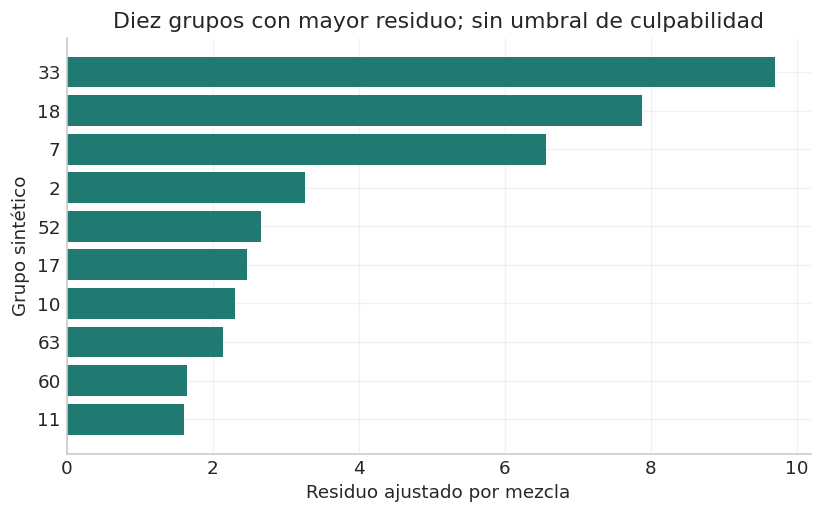

In [3]:
tau=40.
process['tasa_contraida']=(process['O']+tau*process['tasa_esperada'])/(process['n']+tau)
process['exceso_contraido']=process['tasa_contraida']-process['tasa_esperada']
ranked=process.sort_values('z',ascending=False).head(10)
display(ranked[['grupo','n','tasa_bruta','tasa_esperada','tasa_contraida','z','anomalia_simulada']])
fig,ax=plt.subplots();ax.barh(ranked['grupo'].astype(str),ranked['z'],color=TEAL)
ax.invert_yaxis();ax.set(xlabel='Residuo ajustado por mezcla',ylabel='Grupo sintético',title='Diez grupos con mayor residuo; sin umbral de culpabilidad');plt.show()

El ranking ofrece una prioridad de investigación, no significancia corregida por probar 80 grupos. Una contracción fuerte puede ocultar cambios reales en grupos pequeños; debe contrastarse con demora y carga de casos.

## 3. Sensibilidad a la fuerza de la referencia


Para $\tau\to0$ se recupera la tasa bruta; para $\tau\to\infty$ la referencia domina. Contar anomalías inyectadas entre los primeros K sirve como diagnóstico del simulador, no como recall de fraude real.

In [4]:
comparison=[]
K=8
for score in ['tasa_bruta','z','exceso_contraido']:
    selected=process.nlargest(K,score)
    comparison.append({'criterio':score,'K':K,'cambios_inyectados_en_K':int(selected['anomalia_simulada'].sum()),'volumen_medio':selected['n'].mean()})
display(pd.DataFrame(comparison))
small=process.nsmallest(1,'n').iloc[0]
tau_table=pd.DataFrame({'tau':[0,10,40,100,1000]})
tau_table['tasa_contraida']=(small['O']+tau_table['tau']*small['tasa_esperada'])/(small['n']+tau_table['tau'])
display(tau_table)

,criterio,K,cambios_inyectados_en_K,volumen_medio
0,tasa_bruta,8,3,59.6250
1,z,8,4,140.1250
2,exceso_contraido,8,4,117.0000


,tau,tasa_contraida
0,0,0.2000
1,10,0.1562
2,40,0.1300
3,100,0.1205
4,1000,0.1134


No elegimos tau con el conteo de anomalías de este test. Una extensión debe separar entrenamiento y validación, estimar la mezcla sin fuga y considerar correlación dentro del canal y a través del tiempo.

## Comprobaciones y límites

Las identidades y contraejemplos siguientes son parte del experimento; no verifican desempeño productivo.

In [5]:
assert ((process['tasa_contraida']>=process[['tasa_bruta','tasa_esperada']].min(axis=1)-1e-12)&(process['tasa_contraida']<=process[['tasa_bruta','tasa_esperada']].max(axis=1)+1e-12)).all()
assert process['n'].min()>0
assert np.isfinite(process['z']).all()

## Resultados computados

In [6]:
metrics = {'Grupos simulados': groups, 'Cambios inyectados': int(anomalous.sum()), 'Grupos revisados por criterio': K, 'Mayor residuo ajustado': round(float(process['z'].max()),3)}
print("LAB_METRICS:" + json.dumps(metrics, ensure_ascii=False))

LAB_METRICS:{"Grupos simulados": 80, "Cambios inyectados": 4, "Grupos revisados por criterio": 8, "Mayor residuo ajustado": 9.7}


## Ideas y preguntas para continuar

1. Estimar tasas base por producto en una ventana histórica cerrada.
2. Ajustar sobredispersión y dependencia por lotes antes de usar p-valores.
3. Comparar contracción con modelo jerárquico de efectos de grupo.
4. Incluir versión de política y cambios de logging como explicaciones alternativas.
5. Diseñar un presupuesto de alertas y criterios de escalamiento, no acusaciones automáticas.

## Fuentes y relación con el proyecto

La referencia y las anomalías se conocen solo por construcción del simulador. La contracción es una identidad algebraica explícita; no se presenta como un modelo bayesiano estimado. Proyecto: `../README.md`.

Consultar también `../README.md` y `../../MODEL_AND_LOSS_METHODS.md`.